In [10]:
# !pip install evaluate -q
!pip install torch==2.6.0 torchvision==0.21.0 --force-reinstall
!pip install transformers==4.41.2 --force-reinstall
!pip uninstall -y peft
!pip install datasets==2.19.1
!pip install numpy==1.26.4 --force-reinstall
# !pip install accelerate


  Using cached torch-2.6.0-cp312-cp312-manylinux1_x86_64.whl.metadata (28 kB)
  Using cached torchvision-0.21.0-cp312-cp312-manylinux1_x86_64.whl.metadata (6.1 kB)
  Using cached filelock-4.0.8-py3-none-any.whl.metadata (2.0 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached nvidia_cuda_nvrtc_cu12-12.4.127-py3-none-manylinux2014_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_runtime_cu12-12.4.127-py3-none-manylinux2014_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_cupti_cu12-12.4.127-py3-none-manylinux2014_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cudnn_cu12-9.1.0.70-py3-none-manylinux2014_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cublas_cu12-12.4.5.8-py3-none-manylinux2014_x86_64.whl.metadata (1.5 kB)
  Using cached nv

  Using cached transformers-4.41.2-py3-none-any.whl.metadata (43 kB)
  Using cached filelock-4.0.8-py3-none-any.whl.metadata (2.0 kB)
  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
  Using cached numpy-2.5.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.4 kB)
  Using cached regex-2026.9.29-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tokenizers-0.19.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.7 kB)
  Using cached safetensors-0.8.0-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.2 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached fsspec-

  Using cached fsspec-2024.3.1-py3-none-any.whl.metadata (6.8 kB)
Using cached fsspec-2024.3.1-py3-none-any.whl (171 kB)
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.9.0
    Uninstalling fsspec-2026.9.0:
      Successfully uninstalled fsspec-2026.9.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.3.1 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled num

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# ==========================================
# IMPORT LIBRARY
# ==========================================

import seaborn as sns
import os
import gc
import numpy as np
import pandas as pd
import torch

from datasets import Dataset

from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

import matplotlib.pyplot as plt

In [3]:
# Baca dataset
df = pd.read_csv('/content/drive/MyDrive/SKRIPSI/data_opini_preprocessed.csv')

texts = df["text"].astype(str).tolist()
# Pastikan tidak ada data kosong
df = df.dropna(subset=['text', 'label'])
df.head()

,text,stance,label
0,ada food estate papua manfaat masyarakat penuh...,0,Pro
1,tanah papua semangat mandiri pangan indonesia ...,0,Pro
2,papua kembang pesat wilayah strategis daerah t...,3,Netral
3,kaya alam budaya timur indonesia simbol kuat b...,3,Netral
4,food estate merauke bukti bangun inklusif manu...,0,Pro


# **EXPLORATORY DATA ANALYSIS (EDA)**

## **distribusi label**

label
Kontra    382
Pro       376
Netral    253
Name: count, dtype: int64


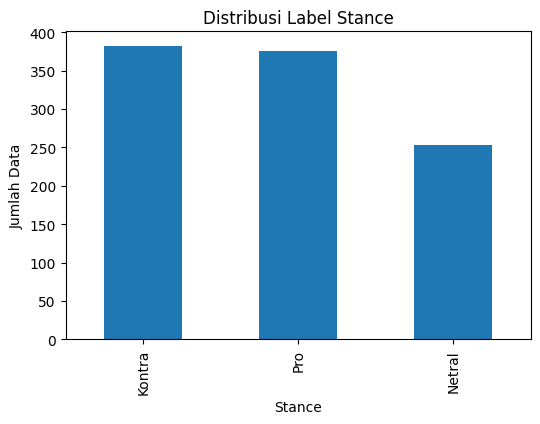

In [ ]:
stance_counts = df['label'].value_counts()

print(stance_counts)

plt.figure(figsize=(6,4))
stance_counts.plot(kind='bar')
plt.title('Distribusi Label Stance')
plt.xlabel('Stance')
plt.ylabel('Jumlah Data')
plt.show()

##**pie chart distribusi**

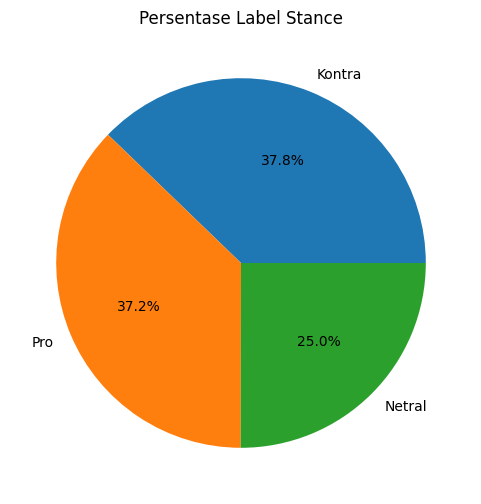

In [ ]:
plt.figure(figsize=(6,6))
df['label'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)
plt.ylabel('')
plt.title('Persentase Label Stance')
plt.show()

##**distribusi panjang komentar**

In [ ]:
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))

df['word_count'].describe()

,word_count
count,1011.000000
mean,19.222552
std,14.978563
min,1.000000
25%,9.000000
50%,15.000000
75%,25.000000
max,157.000000


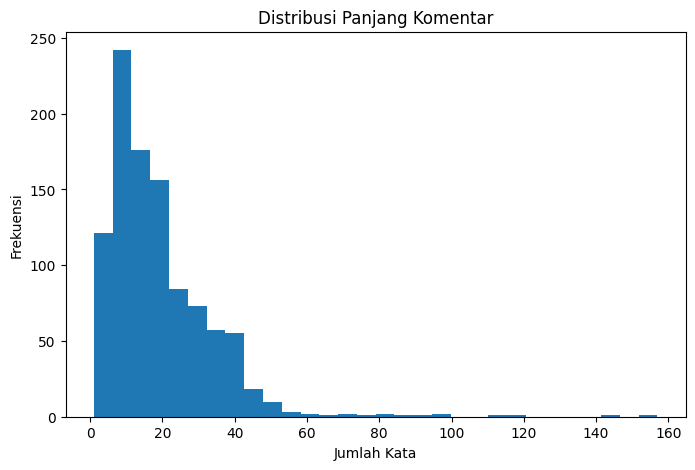

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['word_count'], bins=30)
plt.title('Distribusi Panjang Komentar')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.show()

##**boxplot panjang komentar**

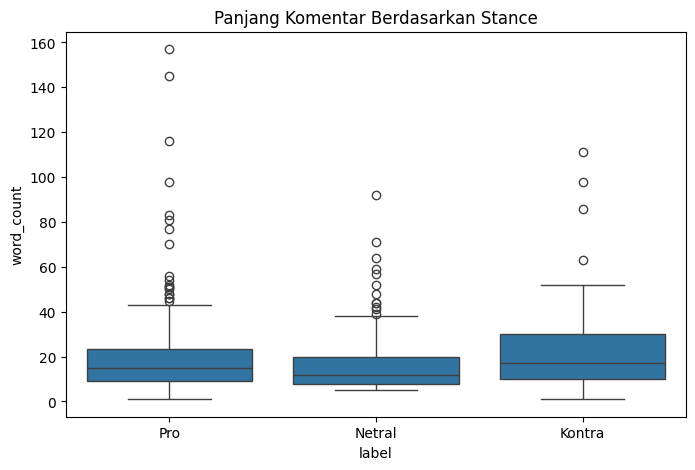

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x='label',
    y='word_count',
    data=df
)

plt.title('Panjang Komentar Berdasarkan Stance')
plt.show()

##**wordcloud label pro**

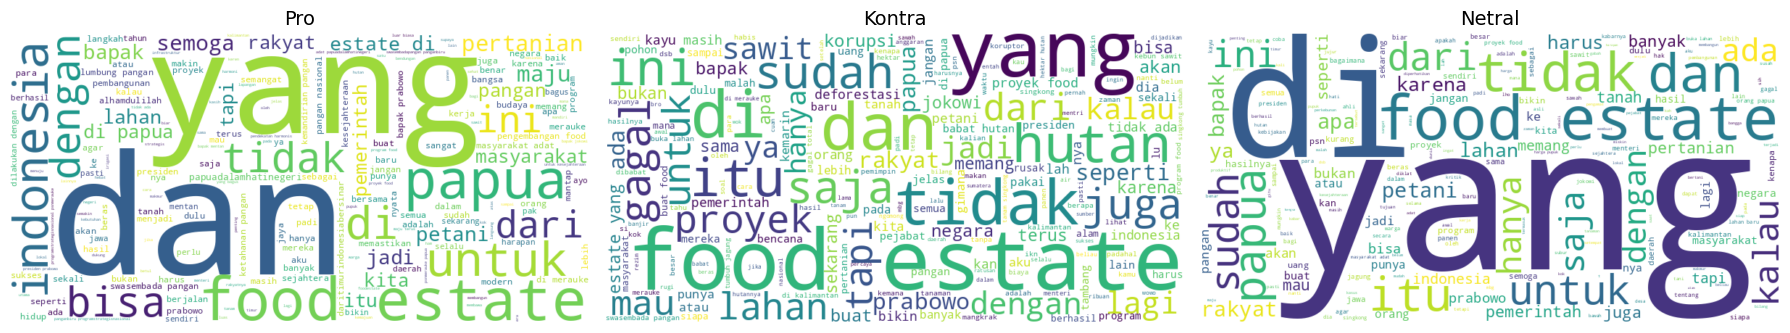

In [ ]:
texts = {
    'Pro': ' '.join(df[df['label']=='Pro']['text'].astype(str)),
    'Kontra': ' '.join(df[df['label']=='Kontra']['text'].astype(str)),
    'Netral': ' '.join(df[df['label']=='Netral']['text'].astype(str))
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (label, text) in zip(axes, texts.items()):
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(label, fontsize=14)
    ax.axis('off')

plt.tight_layout()
plt.show()

##**top 20 kata per stance**

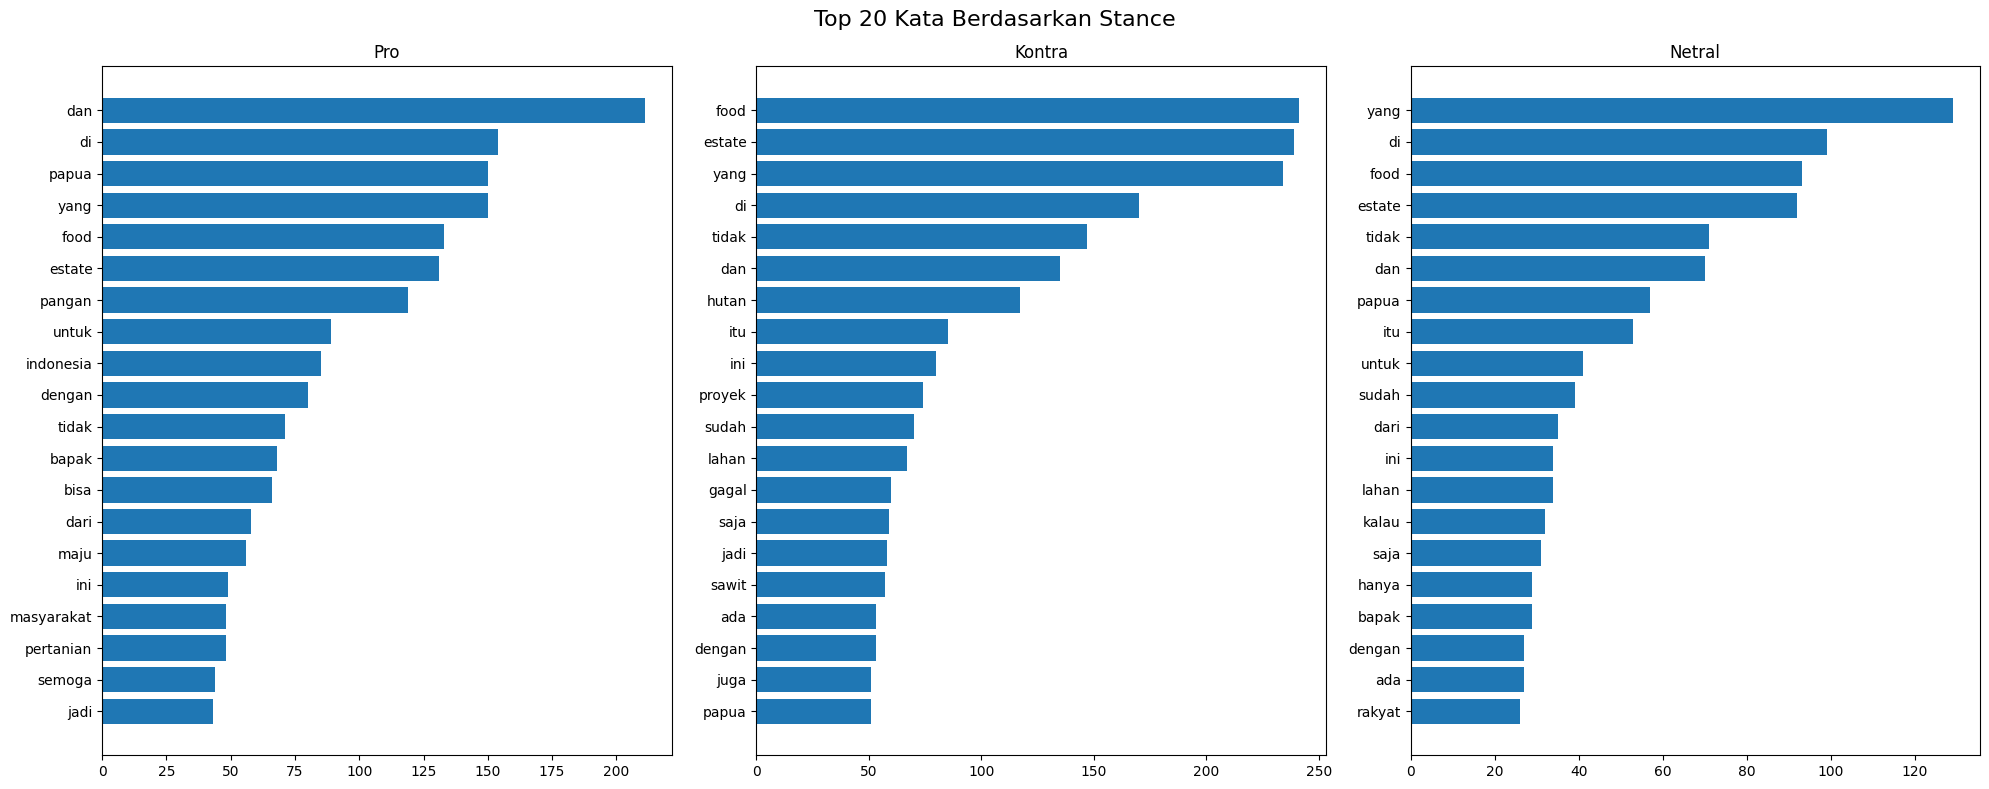

In [ ]:
# Fungsi mengambil top words
def get_top_words(text_series, n=20):
    words = ' '.join(text_series.astype(str)).split()
    return pd.DataFrame(
        Counter(words).most_common(n),
        columns=['kata', 'frekuensi']
    )

# Ambil top words masing-masing stance
pro_df = get_top_words(
    df[df['label'] == 'Pro']['text']
)

kontra_df = get_top_words(
    df[df['label'] == 'Kontra']['text']
)

netral_df = get_top_words(
    df[df['label'] == 'Netral']['text']
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Pro
axes[0].barh(
    pro_df['kata'],
    pro_df['frekuensi']
)
axes[0].set_title('Pro')
axes[0].invert_yaxis()

# Kontra
axes[1].barh(
    kontra_df['kata'],
    kontra_df['frekuensi']
)
axes[1].set_title('Kontra')
axes[1].invert_yaxis()

# Netral
axes[2].barh(
    netral_df['kata'],
    netral_df['frekuensi']
)
axes[2].set_title('Netral')
axes[2].invert_yaxis()

plt.suptitle(
    'Top 20 Kata Berdasarkan Stance',
    fontsize=16
)

plt.tight_layout()
plt.show()

##**top 10 bigram**

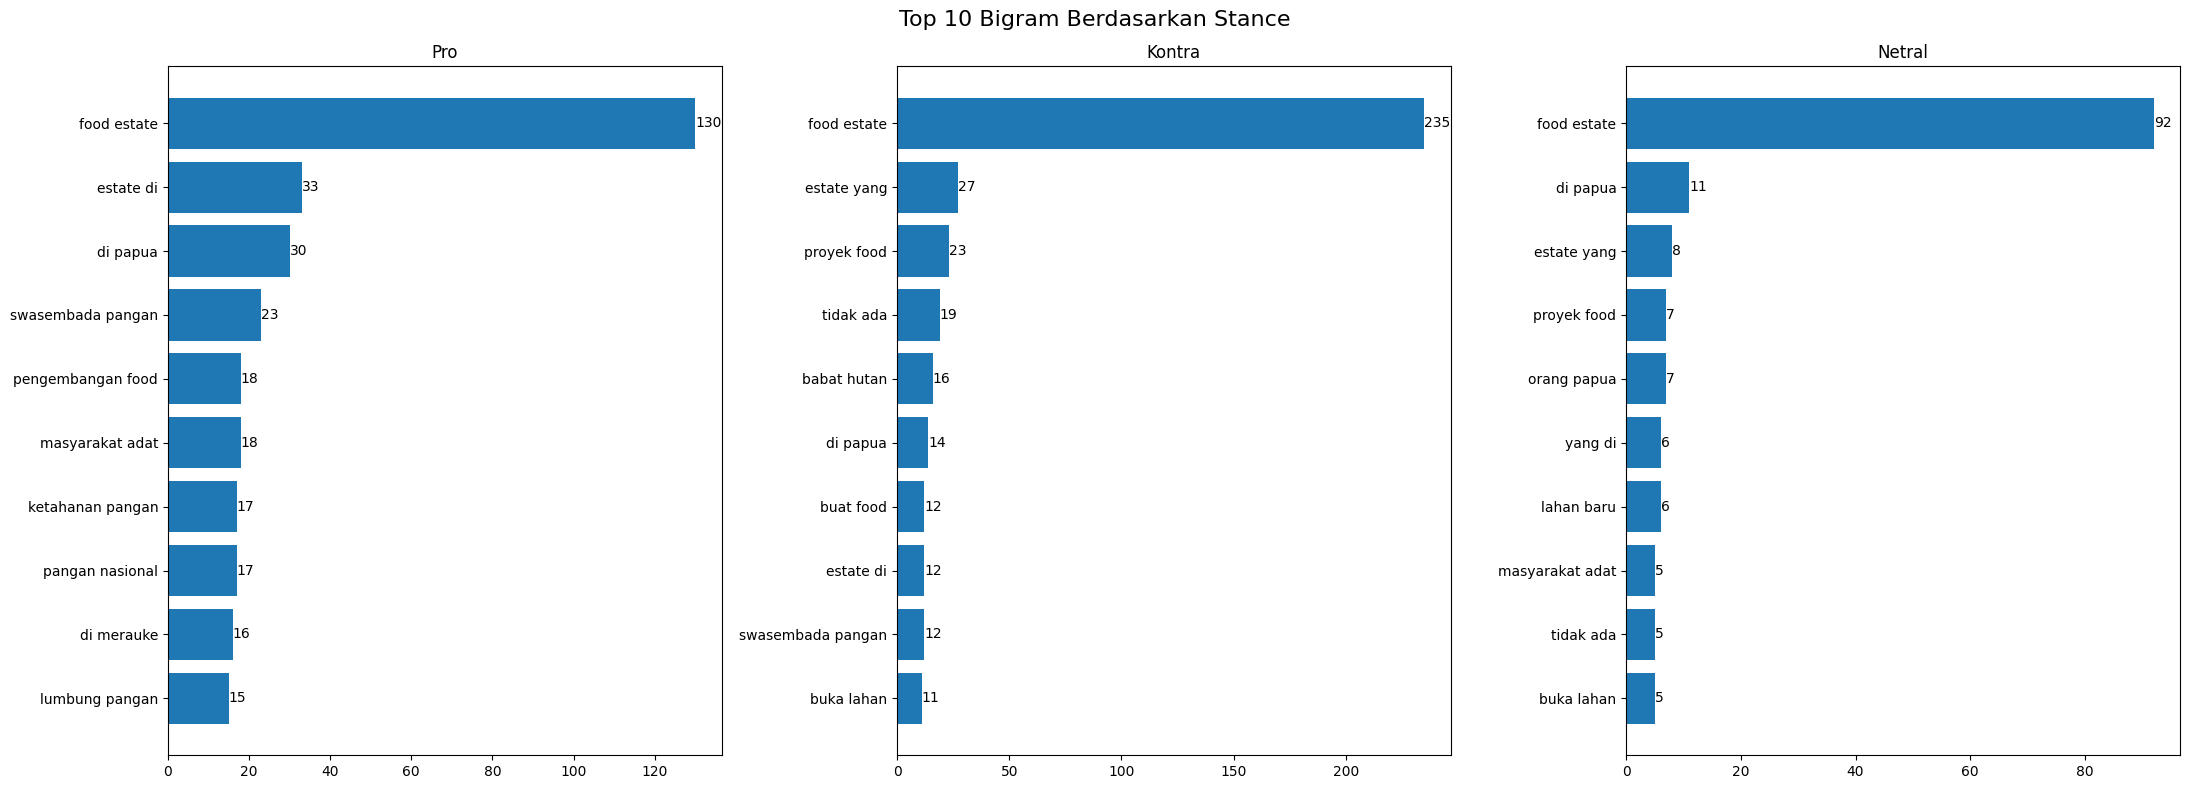

In [ ]:
# Fungsi mengambil top bigram
def get_top_bigrams(text_series, n=10):

    words = ' '.join(
        text_series.astype(str)
    ).split()

    bigram_freq = Counter(
        bigrams(words)
    ).most_common(n)

    bigram_df = pd.DataFrame(
        bigram_freq,
        columns=['bigram', 'frekuensi']
    )

    bigram_df['bigram'] = bigram_df['bigram'].apply(
        lambda x: ' '.join(x)
    )

    return bigram_df

# Ambil bigram tiap stance
pro_bigram = get_top_bigrams(
    df[df['label'] == 'Pro']['text']
)

kontra_bigram = get_top_bigrams(
    df[df['label'] == 'Kontra']['text']
)

netral_bigram = get_top_bigrams(
    df[df['label'] == 'Netral']['text']
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# PRO
axes[0].barh(
    pro_bigram['bigram'],
    pro_bigram['frekuensi']
)
axes[0].set_title('Pro')
axes[0].invert_yaxis()

for i, v in enumerate(pro_bigram['frekuensi']):
    axes[0].text(v, i, str(v), va='center')

# KONTRA
axes[1].barh(
    kontra_bigram['bigram'],
    kontra_bigram['frekuensi']
)
axes[1].set_title('Kontra')
axes[1].invert_yaxis()

for i, v in enumerate(kontra_bigram['frekuensi']):
    axes[1].text(v, i, str(v), va='center')

# NETRAL
axes[2].barh(
    netral_bigram['bigram'],
    netral_bigram['frekuensi']
)
axes[2].set_title('Netral')
axes[2].invert_yaxis()

for i, v in enumerate(netral_bigram['frekuensi']):
    axes[2].text(v, i, str(v), va='center')

plt.suptitle(
    'Top 10 Bigram Berdasarkan Stance',
    fontsize=16
)

plt.tight_layout()
plt.show()

##**jumlah kata sebelum dan sesudah preprocessing**

In [ ]:
raw_df = pd.read_csv('/content/drive/MyDrive/SKRIPSI/data_opini.csv')
raw_words = raw_df['text'].astype(str).str.split().str.len().sum()

clean_words = df['text'].astype(str).str.split().str.len().sum()

print("Sebelum:", raw_words)
print("Sesudah:", clean_words)

Sebelum: 20412
Sesudah: 19434


In [ ]:
print("Jumlah Data :", len(df))

print("Jumlah Pro :",
      len(df[df['stance']==0]))

print("Jumlah Kontra :",
      len(df[df['stance']==2]))

print("Jumlah Netral :",
      len(df[df['stance']==3]))

print("Rata-rata kata :",
      round(df['word_count'].mean(),2))

print("Komentar terpanjang :",
      df['word_count'].max())

print("Komentar terpendek :",
      df['word_count'].min())

Jumlah Data : 1011
Jumlah Pro : 376
Jumlah Kontra : 382
Jumlah Netral : 253
Rata-rata kata : 19.22
Komentar terpanjang : 157
Komentar terpendek : 1


#**DATA SPLIT**

In [4]:
# ==========================================
# DATASET
# ==========================================

label2id = {
    "Pro": 0,
    "Kontra": 1,
    "Netral": 2
}

id2label = {
    0: "Pro",
    1: "Kontra",
    2: "Netral"
}

df["label"] = df["label"].map(label2id)

df = df.dropna(subset=["text", "label"]).reset_index(drop=True)

df["label"] = df["label"].astype(int)

print("Jumlah data:", len(df))
print("\nDistribusi label:")
print(df["label"].value_counts())

Jumlah data: 1010

Distribusi label:
label
1    382
0    375
2    253
Name: count, dtype: int64


In [5]:
# ==========================================
# MODEL DAN TOKENIZER
# ==========================================

MODEL_NAME = "indobenchmark/indobert-base-p1"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer berhasil dimuat.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer berhasil dimuat.


In [6]:
# ==========================================
# FUNGSI TOKENISASI
# ==========================================

def tokenize_dataset(dataset, max_length):

    def tokenize_function(examples):

        return tokenizer(
            examples["text"],
            padding="max_length",
            truncation=True,
            max_length=max_length
        )

    dataset = dataset.map(
        tokenize_function,
        batched=True
    )

    dataset = dataset.rename_column(
        "label",
        "labels"
    )

    dataset.set_format(
        type="torch",
        columns=[
            "input_ids",
            "attention_mask",
            "labels"
        ]
    )

    return dataset

In [7]:
# ==========================================
# FUNGSI CREATE MODEL
# ==========================================

def create_model():

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3
    )
    model.config.problem_type = "single_label_classification"

    return model

In [8]:
# ==========================================
# FUNGSI METRICS
# ==========================================

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [9]:
# ==========================================
# HYPERPARAMETER GRID
# ==========================================

grid = [
    # Learning rate 1e-5
    {
        "learning_rate": 1e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 8,
        "max_length": 64
    },
    {
        "learning_rate": 1e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 8,
        "max_length": 128
    },
    {
        "learning_rate": 1e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 16,
        "max_length": 64
    },
    {
        "learning_rate": 1e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 16,
        "max_length": 128
    },

    # Learning rate 2e-5
    {
        "learning_rate": 2e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 8,
        "max_length": 64
    },
    {
        "learning_rate": 2e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 8,
        "max_length": 128
    },
    {
        "learning_rate": 2e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 16,
        "max_length": 64
    },
    {
        "learning_rate": 2e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 16,
        "max_length": 128
    },

    # Learning rate 3e-5
    {
        "learning_rate": 3e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 8,
        "max_length": 64
    },
    {
        "learning_rate": 3e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 8,
        "max_length": 128
    },
    {
        "learning_rate": 3e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 16,
        "max_length": 64
    },
    {
        "learning_rate": 3e-5,
        "num_train_epochs": 2,
        "per_device_train_batch_size": 16,
        "max_length": 128
    }
]

print("Jumlah trial:", len(grid))

for i, params in enumerate(grid, start=1):

    print(f"\nTrial {i}:")
    print(params)

Jumlah trial: 12

Trial 1:
{'learning_rate': 1e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 8, 'max_length': 64}

Trial 2:
{'learning_rate': 1e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 8, 'max_length': 128}

Trial 3:
{'learning_rate': 1e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 16, 'max_length': 64}

Trial 4:
{'learning_rate': 1e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 16, 'max_length': 128}

Trial 5:
{'learning_rate': 2e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 8, 'max_length': 64}

Trial 6:
{'learning_rate': 2e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 8, 'max_length': 128}

Trial 7:
{'learning_rate': 2e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 16, 'max_length': 64}

Trial 8:
{'learning_rate': 2e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 16, 'max_length': 128}

Trial 9:
{'learning_rate': 3e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 8, 'ma

In [10]:
# ==========================================
# PILIH OUTER FOLD
# ==========================================

FOLD_NUMBER = 5

print(
    f"Outer Fold yang dipilih: "
    f"{FOLD_NUMBER}/5"
)

Outer Fold yang dipilih: 5/5


In [11]:
# ==========================================
# STRATIFIED 5-FOLD
# ==========================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_splits = list(
    skf.split(
        df["text"],
        df["label"]
    )
)

train_idx, val_idx = fold_splits[
    FOLD_NUMBER - 1
]

train_df = df.iloc[
    train_idx
].reset_index(drop=True)

val_df = df.iloc[
    val_idx
].reset_index(drop=True)

print("=" * 70)
print(
    f"OUTER FOLD {FOLD_NUMBER}/5"
)
print("=" * 70)

print(
    "Outer train      :",
    len(train_df)
)

print(
    "Outer validation :",
    len(val_df)
)

OUTER FOLD 5/5
Outer train      : 808
Outer validation : 202


In [12]:
# ==========================================
# FOLDER HPO
# ==========================================

HPO_DIR = (
    "/content/drive/MyDrive/"
    "SKRIPSI/IndoBERT_HPO"
)

os.makedirs(
    HPO_DIR,
    exist_ok=True
)

print("Folder HPO:")
print(HPO_DIR)

Folder HPO:
/content/drive/MyDrive/SKRIPSI/IndoBERT_HPO


In [13]:
# ==========================================
# INNER STRATIFIED SPLIT
# ==========================================

inner_train_df, inner_val_df = train_test_split(
    train_df,
    test_size=0.2,
    stratify=train_df["label"],
    random_state=42
)

inner_train_df = (
    inner_train_df
    .reset_index(drop=True)
)

inner_val_df = (
    inner_val_df
    .reset_index(drop=True)
)

print("=" * 70)

print(
    "Inner train      :",
    len(inner_train_df)
)

print(
    "Inner validation :",
    len(inner_val_df)
)

Inner train      : 646
Inner validation : 162


In [ ]:
# ==========================================
# HYPERPARAMETER OPTIMIZATION
# ==========================================

print("=" * 70)
print(
    f"START HPO - OUTER FOLD {FOLD_NUMBER}"
)
print("=" * 70)

print(
    f"Jumlah trial: {len(grid)}"
)


# ==========================================
# LOOP SEMUA TRIAL
# ==========================================

for trial_number, params in enumerate(
    grid,
    start=1
):

    print("\n")
    print("=" * 70)
    print(
        f"FOLD {FOLD_NUMBER} "
        f"- TRIAL {trial_number}/{len(grid)}"
    )
    print("=" * 70)

    print(
        f"\nLearning rate : "
        f"{params['learning_rate']}"
    )

    print(
        f"Epoch         : "
        f"{params['num_train_epochs']}"
    )

    print(
        f"Batch size    : "
        f"{params['per_device_train_batch_size']}"
    )

    print(
        f"Max length    : "
        f"{params['max_length']}"
    )


    # ======================================
    # CEK APAKAH TRIAL SUDAH SELESAI
    # ======================================

    trial_path = (
        f"{HPO_DIR}/"
        f"fold_{FOLD_NUMBER}_"
        f"trial_{trial_number}.csv"
    )

    if os.path.exists(trial_path):

        print(
            "\nTrial ini sudah selesai."
        )

        print(
            "Melewati trial..."
        )

        continue


    # ======================================
    # CREATE DATASET
    # ======================================

    train_dataset = Dataset.from_pandas(
        inner_train_df[
            ["text", "label"]
        ],
        preserve_index=False
    )

    val_dataset = Dataset.from_pandas(
        inner_val_df[
            ["text", "label"]
        ],
        preserve_index=False
    )


    # ======================================
    # TOKENISASI
    # ======================================

    train_dataset = tokenize_dataset(
        train_dataset,
        params["max_length"]
    )

    val_dataset = tokenize_dataset(
        val_dataset,
        params["max_length"]
    )


    # ======================================
    # TRAINING ARGUMENTS
    # ======================================

    training_args = TrainingArguments(

        output_dir=(
            f"/content/"
            f"hpo_fold_{FOLD_NUMBER}_"
            f"trial_{trial_number}"
        ),

        eval_strategy="epoch",

        # Tidak menyimpan checkpoint
        save_strategy="no",

        # Tetap mencatat training log
        logging_strategy="epoch",

        learning_rate=
            params["learning_rate"],

        num_train_epochs=
            params["num_train_epochs"],

        per_device_train_batch_size=
            params[
                "per_device_train_batch_size"
            ],

        per_device_eval_batch_size=
            params[
                "per_device_train_batch_size"
            ],

        load_best_model_at_end=False,

        report_to="none",

        fp16=torch.cuda.is_available(),

        seed=42
    )


    # ======================================
    # CREATE MODEL
    # ======================================

    model = create_model()


    # ======================================
    # CREATE TRAINER
    # ======================================

    trainer = Trainer(

        model=model,

        args=training_args,

        train_dataset=train_dataset,

        eval_dataset=val_dataset,

        compute_metrics=compute_metrics
    )


    # ======================================
    # TRAINING
    # ======================================

    print("\nTraining dimulai...")

    trainer.train()

    print(
        "\nTraining selesai."
    )


    # ======================================
    # EVALUASI
    # ======================================

    result = trainer.evaluate()


    # ======================================
    # SIMPAN HASIL TRIAL
    # ======================================

    trial_result = pd.DataFrame([{

        "fold":
            FOLD_NUMBER,

        "trial":
            trial_number,

        "learning_rate":
            params["learning_rate"],

        "epochs":
            params["num_train_epochs"],

        "batch_size":
            params[
                "per_device_train_batch_size"
            ],

        "max_length":
            params["max_length"],

        "accuracy":
            result["eval_accuracy"],

        "precision":
            result["eval_precision"],

        "recall":
            result["eval_recall"],

        "f1":
            result["eval_f1"]

    }])


    trial_result.to_csv(
        trial_path,
        index=False
    )


    # ======================================
    # SIMPAN TRAINING LOG
    # ======================================

    logs_df = pd.DataFrame(
        trainer.state.log_history
    )

    log_path = (
        f"{HPO_DIR}/"
        f"fold_{FOLD_NUMBER}_"
        f"trial_{trial_number}_logs.csv"
    )

    logs_df.to_csv(
        log_path,
        index=False
    )


    # ======================================
    # TAMPILKAN HASIL
    # ======================================

    print("\n")
    print("-" * 70)
    print(
        f"HASIL TRIAL {trial_number}"
    )
    print("-" * 70)

    print(
        f"Accuracy : "
        f"{result['eval_accuracy']:.4f}"
    )

    print(
        f"Precision: "
        f"{result['eval_precision']:.4f}"
    )

    print(
        f"Recall   : "
        f"{result['eval_recall']:.4f}"
    )

    print(
        f"F1       : "
        f"{result['eval_f1']:.4f}"
    )

    print(
        "\nHasil disimpan:"
    )

    print(trial_path)


    # ======================================
    # CLEAN MEMORY
    # ======================================

    del trainer
    del model
    del train_dataset
    del val_dataset

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(
        "\nMemory berhasil dibersihkan."
    )


print("\n")
print("=" * 70)
print(
    f"HPO FOLD {FOLD_NUMBER} SELESAI"
)
print("=" * 70)

START HPO - OUTER FOLD 5
Jumlah trial: 12


FOLD 5 - TRIAL 1/12

Learning rate : 1e-05
Epoch         : 2
Batch size    : 8
Max length    : 64

Trial ini sudah selesai.
Melewati trial...


FOLD 5 - TRIAL 2/12

Learning rate : 1e-05
Epoch         : 2
Batch size    : 8
Max length    : 128

Trial ini sudah selesai.
Melewati trial...


FOLD 5 - TRIAL 3/12

Learning rate : 1e-05
Epoch         : 2
Batch size    : 16
Max length    : 64

Trial ini sudah selesai.
Melewati trial...


FOLD 5 - TRIAL 4/12

Learning rate : 1e-05
Epoch         : 2
Batch size    : 16
Max length    : 128

Trial ini sudah selesai.
Melewati trial...


FOLD 5 - TRIAL 5/12

Learning rate : 2e-05
Epoch         : 2
Batch size    : 8
Max length    : 64

Trial ini sudah selesai.
Melewati trial...


FOLD 5 - TRIAL 6/12

Learning rate : 2e-05
Epoch         : 2
Batch size    : 8
Max length    : 128

Trial ini sudah selesai.
Melewati trial...


FOLD 5 - TRIAL 7/12

Learning rate : 2e-05
Epoch         : 2
Batch size    : 16
Max len

In [14]:
# ==========================================
# HASIL HPO FOLD
# ==========================================

import glob

hpo_files = glob.glob(
    f"{HPO_DIR}/"
    f"fold_{FOLD_NUMBER}_trial_*.csv"
)

hpo_files = [
    f for f in hpo_files
    if "_logs.csv" not in f
]

hpo_fold = pd.concat(
    [
        pd.read_csv(f)
        for f in hpo_files
    ],
    ignore_index=True
)

hpo_fold = hpo_fold.sort_values(
    "f1",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print(
    f"HASIL HPO FOLD {FOLD_NUMBER}"
)
print("=" * 70)

display(hpo_fold)

HASIL HPO FOLD 5


,fold,trial,learning_rate,epochs,batch_size,max_length,accuracy,precision,recall,f1
0,5,10,0.00003,2,8,128,0.691358,0.674961,0.691358,0.679213
1,5,9,0.00003,2,8,64,0.691358,0.673688,0.691358,0.677103
2,5,5,0.00002,2,8,64,0.685185,0.664670,0.685185,0.667783
3,5,6,0.00002,2,8,128,0.679012,0.660231,0.679012,0.661627
4,5,1,0.00001,2,8,64,0.672840,0.659959,0.672840,0.638729
5,5,12,0.00003,2,16,128,0.666667,0.649143,0.666667,0.633825
6,5,2,0.00001,2,8,128,0.672840,0.662092,0.672840,0.633732
7,5,7,0.00002,2,16,64,0.660494,0.643714,0.660494,0.628209
8,5,11,0.00003,2,16,64,0.660494,0.629593,0.660494,0.625854
9,5,8,0.00002,2,16,128,0.654321,0.632674,0.654321,0.613397


In [15]:
# ==========================================
# BEST HYPERPARAMETER
# ==========================================

best_params = {

    "learning_rate":
        hpo_fold.loc[
            0,
            "learning_rate"
        ],

    "num_train_epochs":
        int(
            hpo_fold.loc[
                0,
                "epochs"
            ]
        ),

    "per_device_train_batch_size":
        int(
            hpo_fold.loc[
                0,
                "batch_size"
            ]
        ),

    "max_length":
        int(
            hpo_fold.loc[
                0,
                "max_length"
            ]
        )
}

print("=" * 70)
print("BEST HYPERPARAMETER")
print("=" * 70)

for key, value in best_params.items():

    print(
        f"{key}: {value}"
    )

BEST HYPERPARAMETER
learning_rate: 3e-05
num_train_epochs: 2
per_device_train_batch_size: 8
max_length: 128


#**SETELAH SEMUANYA SELESAI ANJAY**

In [16]:
import os
import glob
import pandas as pd

HPO_DIR = "/content/drive/MyDrive/SKRIPSI/IndoBERT_HPO"

files = glob.glob(
    os.path.join(HPO_DIR, "fold_*_trial_*.csv")
)

# Jangan ikut membaca file log
files = [
    f for f in files
    if not f.endswith("_logs.csv")
]

print("=" * 60)
print("HASIL HPO")
print("=" * 60)
print(f"Jumlah file trial : {len(files)}")

results = []

required_columns = [
    "fold",
    "trial",
    "learning_rate",
    "epochs",
    "batch_size",
    "max_length",
    "accuracy",
    "precision",
    "recall",
    "f1"
]

for file in files:

    temp = pd.read_csv(file)

    # Hanya ambil file hasil trial yang valid
    if all(col in temp.columns for col in required_columns):
        results.append(temp[required_columns])

hpo_results = pd.concat(
    results,
    ignore_index=True
)

print(f"Jumlah hasil      : {len(hpo_results)}")

display(hpo_results)

HASIL HPO
Jumlah file trial : 60
Jumlah hasil      : 60


,fold,trial,learning_rate,epochs,batch_size,max_length,accuracy,precision,recall,f1
0,1,1,0.00001,2,8,128,0.709877,0.694463,0.709877,0.695390
1,1,2,0.00001,2,16,128,0.679012,0.666438,0.679012,0.644770
2,1,3,0.00002,2,8,128,0.679012,0.674379,0.679012,0.675980
3,1,4,0.00002,2,16,128,0.685185,0.673208,0.685185,0.677780
4,1,5,0.00003,2,8,128,0.691358,0.686998,0.691358,0.687798
5,1,6,0.00003,2,16,128,0.685185,0.685101,0.685185,0.684884
6,1,7,0.00002,2,16,64,0.697531,0.684119,0.697531,0.687693
7,1,8,0.00002,2,16,128,0.685185,0.673208,0.685185,0.677780
8,1,9,0.00003,2,8,64,0.679012,0.669285,0.679012,0.673060
9,1,10,0.00003,2,8,128,0.691358,0.686998,0.691358,0.687798


In [17]:
config_summary = (
    hpo_results
    .groupby(
        [
            "learning_rate",
            "epochs",
            "batch_size",
            "max_length"
        ]
    )
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),

        mean_precision=("precision", "mean"),
        std_precision=("precision", "std"),

        mean_recall=("recall", "mean"),
        std_recall=("recall", "std"),

        mean_f1=("f1", "mean"),
        std_f1=("f1", "std")
    )
    .reset_index()
)

config_summary = config_summary.sort_values(
    "mean_f1",
    ascending=False
)

display(config_summary)

,learning_rate,epochs,batch_size,max_length,mean_accuracy,std_accuracy,mean_precision,std_precision,mean_recall,std_recall,mean_f1,std_f1
5,0.00002,2,8,128,0.714815,0.035299,0.705747,0.038644,0.714815,0.035299,0.707207,0.038372
4,0.00002,2,8,64,0.716049,0.038384,0.703172,0.043443,0.716049,0.038384,0.706025,0.042804
8,0.00003,2,8,64,0.711111,0.032488,0.703498,0.036383,0.711111,0.032488,0.705275,0.035065
9,0.00003,2,8,128,0.710905,0.027721,0.702519,0.027151,0.710905,0.027721,0.704748,0.027383
10,0.00003,2,16,64,0.701235,0.038202,0.686451,0.049682,0.701235,0.038202,0.686457,0.050520
11,0.00003,2,16,128,0.690329,0.020442,0.682326,0.023104,0.690329,0.020442,0.680585,0.027578
1,0.00001,2,8,128,0.703704,0.033242,0.686828,0.037779,0.703704,0.033242,0.679050,0.043375
7,0.00002,2,16,128,0.691358,0.036623,0.674805,0.040735,0.691358,0.036623,0.674283,0.045854
6,0.00002,2,16,64,0.691358,0.021383,0.675359,0.024102,0.691358,0.021383,0.673617,0.032149
0,0.00001,2,8,64,0.695988,0.038508,0.672929,0.049469,0.695988,0.038508,0.667546,0.053160


In [18]:
hpo_ranking = config_summary.copy()

hpo_ranking["mean_accuracy"] *= 100
hpo_ranking["std_accuracy"] *= 100

hpo_ranking["mean_precision"] *= 100
hpo_ranking["std_precision"] *= 100

hpo_ranking["mean_recall"] *= 100
hpo_ranking["std_recall"] *= 100

hpo_ranking["mean_f1"] *= 100
hpo_ranking["std_f1"] *= 100

display(
    hpo_ranking[
        [
            "learning_rate",
            "epochs",
            "batch_size",
            "max_length",
            "mean_accuracy",
            "mean_precision",
            "mean_recall",
            "mean_f1",
            "std_f1"
        ]
    ].round(2)
)

,learning_rate,epochs,batch_size,max_length,mean_accuracy,mean_precision,mean_recall,mean_f1,std_f1
5,0.0,2,8,128,71.48,70.57,71.48,70.72,3.84
4,0.0,2,8,64,71.60,70.32,71.60,70.60,4.28
8,0.0,2,8,64,71.11,70.35,71.11,70.53,3.51
9,0.0,2,8,128,71.09,70.25,71.09,70.47,2.74
10,0.0,2,16,64,70.12,68.65,70.12,68.65,5.05
11,0.0,2,16,128,69.03,68.23,69.03,68.06,2.76
1,0.0,2,8,128,70.37,68.68,70.37,67.91,4.34
7,0.0,2,16,128,69.14,67.48,69.14,67.43,4.59
6,0.0,2,16,64,69.14,67.54,69.14,67.36,3.21
0,0.0,2,8,64,69.60,67.29,69.60,66.75,5.32


In [19]:
best_config = config_summary.iloc[0]

BEST_LR = float(best_config["learning_rate"])
BEST_EPOCHS = int(best_config["epochs"])
BEST_BATCH_SIZE = int(best_config["batch_size"])
BEST_MAX_LENGTH = int(best_config["max_length"])

print("=== HYPERPARAMETER TERBAIK ===")
print(f"Learning Rate : {BEST_LR}")
print(f"Epochs        : {BEST_EPOCHS}")
print(f"Batch Size    : {BEST_BATCH_SIZE}")
print(f"Max Length    : {BEST_MAX_LENGTH}")
print(f"Mean F1       : {best_config['mean_f1']:.4f}")

=== HYPERPARAMETER TERBAIK ===
Learning Rate : 2e-05
Epochs        : 2
Batch Size    : 8
Max Length    : 128
Mean F1       : 0.7072


# BLABLA

In [36]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

all_y_true = []
all_y_pred = []

fold_results = []

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

for fold, (train_idx, val_idx) in enumerate(
    skf.split(df["text"], df["label"]),
    start=1
):

    print("\n" + "=" * 70)
    print(f"FOLD {fold}")
    print("=" * 70)

    train_df = df.iloc[train_idx].copy()
    val_df = df.iloc[val_idx].copy()

    print(f"Training : {len(train_df)} data")
    print(f"Validasi : {len(val_df)} data")

    # =========================
    # Dataset
    # =========================

    train_dataset = Dataset.from_pandas(
        train_df[
            ["text", "label"]
        ],
        preserve_index=False
    )

    val_dataset = Dataset.from_pandas(
        val_df[
            ["text", "label"]
        ],
        preserve_index=False
    )

    # =========================
    # Tokenisasi
    # =========================

    train_dataset = tokenize_dataset(
        train_dataset,
        BEST_MAX_LENGTH
    )

    val_dataset = tokenize_dataset(
        val_dataset,
        BEST_MAX_LENGTH
    )

    # =========================
    # Model
    # =========================

    model = create_model()
    model.config.problem_type = "single_label_classification"

    # =========================
    # Training Arguments
    # =========================

    training_args = TrainingArguments(

        output_dir=f"/content/indobert_fold_{fold}",
        num_train_epochs=BEST_EPOCHS,

        learning_rate=BEST_LR,

        per_device_train_batch_size=BEST_BATCH_SIZE,
        per_device_eval_batch_size=BEST_BATCH_SIZE,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        report_to="none",
        fp16=torch.cuda.is_available(),
        # seed=42,
        data_seed=42
    )

    # =========================
    # Trainer
    # =========================

    trainer = Trainer(

        model=model,

        args=training_args,

        train_dataset=train_dataset,

        eval_dataset=val_dataset,

        compute_metrics=compute_metrics
    )

    # =========================
    # Training
    # =========================

    trainer.train()

    # =========================
    # Prediction
    # =========================

    predictions = trainer.predict(
        val_dataset
    )

    y_pred = np.argmax(
        predictions.predictions,
        axis=1
    )

    y_true = np.array(
        val_df["label"]
    )

    # Simpan prediksi semua fold
    all_y_true.extend(y_true)
    all_y_pred.extend(y_pred)

    # =========================
    # Metrics per Fold
    # =========================

    fold_accuracy = accuracy_score(
        y_true,
        y_pred
    )

    fold_precision = precision_score(
        y_true,
        y_pred,
        average="weighted"
    )

    fold_recall = recall_score(
        y_true,
        y_pred,
        average="weighted"
    )

    fold_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted"
    )

    fold_results.append({

        "fold": fold,

        "accuracy": fold_accuracy,

        "precision": fold_precision,

        "recall": fold_recall,

        "f1": fold_f1
    })

    print("\nHasil Fold:")
    print(f"Accuracy  : {fold_accuracy*100:.2f}%")
    print(f"Precision : {fold_precision*100:.2f}%")
    print(f"Recall    : {fold_recall*100:.2f}%")
    print(f"F1-Score  : {fold_f1*100:.2f}%")

    # =========================
    # Bersihkan memory
    # =========================

    # del trainer
    # del model
    # del train_dataset
    # del val_dataset

    gc.collect()

    # if torch.cuda.is_available():
    #     torch.cuda.empty_cache()


FOLD 1
Training : 808 data
Validasi : 202 data


Map:   0%|          | 0/808 [00:00<?, ? examples/s]

Map:   0%|          | 0/202 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.808000,0.700675,0.693069,0.708303,0.693069,0.698875
2,0.502300,0.698174,0.702970,0.690321,0.702970,0.692576



Hasil Fold:
Accuracy  : 70.30%
Precision : 69.03%
Recall    : 70.30%
F1-Score  : 69.26%

FOLD 2
Training : 808 data
Validasi : 202 data


... (16 outputs left out)

Map:   0%|          | 0/202 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.842000,0.618574,0.747525,0.770261,0.747525,0.753410
2,0.515600,0.607336,0.757426,0.751613,0.757426,0.753331



Hasil Fold:
Accuracy  : 75.74%
Precision : 75.16%
Recall    : 75.74%
F1-Score  : 75.33%


In [38]:
# =========================================================
# HASIL SETIAP FOLD
# =========================================================

fold_results_df = pd.DataFrame(
    fold_results
)

fold_results_percent = fold_results_df.copy()

for col in [
    "accuracy",
    "precision",
    "recall",
    "f1"
]:
    fold_results_percent[col] *= 100

display(
    fold_results_percent.round(2)
)

,fold,accuracy,precision,recall,f1
0,1,70.30,69.03,70.30,69.26
1,2,71.78,71.59,71.78,71.67
2,3,67.33,67.16,67.33,67.21
3,4,70.30,67.99,70.30,67.40
4,5,75.74,75.16,75.74,75.33


In [39]:
fold_results_percent = fold_results_df.copy()

for col in [
    "accuracy",
    "precision",
    "recall",
    "f1"
]:
    fold_results_percent[col] *= 100

display(
    fold_results_percent.round(2)
)

,fold,accuracy,precision,recall,f1
0,1,70.30,69.03,70.30,69.26
1,2,71.78,71.59,71.78,71.67
2,3,67.33,67.16,67.33,67.21
3,4,70.30,67.99,70.30,67.40
4,5,75.74,75.16,75.74,75.33


In [40]:
mean_accuracy = fold_results_df["accuracy"].mean()
std_accuracy = fold_results_df["accuracy"].std()

mean_precision = fold_results_df["precision"].mean()
std_precision = fold_results_df["precision"].std()

mean_recall = fold_results_df["recall"].mean()
std_recall = fold_results_df["recall"].std()

mean_f1 = fold_results_df["f1"].mean()
std_f1 = fold_results_df["f1"].std()

print("\n" + "=" * 60)
print("HASIL AKHIR MODEL MENGGUNAKAN STRATIFIED 5-FOLD")
print("=" * 60)

print(
    f"Accuracy  : "
    f"{mean_accuracy*100:.2f}% ± {std_accuracy*100:.2f}%"
)

print(
    f"Precision : "
    f"{mean_precision*100:.2f}% ± {std_precision*100:.2f}%"
)

print(
    f"Recall    : "
    f"{mean_recall*100:.2f}% ± {std_recall*100:.2f}%"
)

print(
    f"F1-Score  : "
    f"{mean_f1*100:.2f}% ± {std_f1*100:.2f}%"
)


HASIL AKHIR MODEL MENGGUNAKAN STRATIFIED 5-FOLD
Accuracy  : 71.09% ± 3.06%
Precision : 70.19% ± 3.24%
Recall    : 71.09% ± 3.06%
F1-Score  : 70.17% ± 3.40%


In [41]:
print(
    classification_report(
        all_y_true,
        all_y_pred,
        target_names=[
            "Pro",
            "Kontra",
            "Netral"
        ],
        digits=4
    )
)

accuracy = accuracy_score(
    all_y_true,
    all_y_pred
)

precision = precision_score(
    all_y_true,
    all_y_pred,
    average="weighted"
)

recall = recall_score(
    all_y_true,
    all_y_pred,
    average="weighted"
)

f1 = f1_score(
    all_y_true,
    all_y_pred,
    average="weighted"
)

print(
    "\n=== HASIL GABUNGAN PREDIKSI 5-FOLD ==="
)

print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-Score  : {f1*100:.2f}%")

              precision    recall  f1-score   support

         Pro     0.7955    0.8507    0.8222       375
      Kontra     0.7143    0.7592    0.7360       382
      Netral     0.5369    0.4308    0.4781       253

    accuracy                         0.7109      1010
   macro avg     0.6822    0.6802    0.6788      1010
weighted avg     0.7000    0.7109    0.7034      1010


=== HASIL GABUNGAN PREDIKSI 5-FOLD ===
Accuracy  : 71.09%
Precision : 70.00%
Recall    : 71.09%
F1-Score  : 70.34%


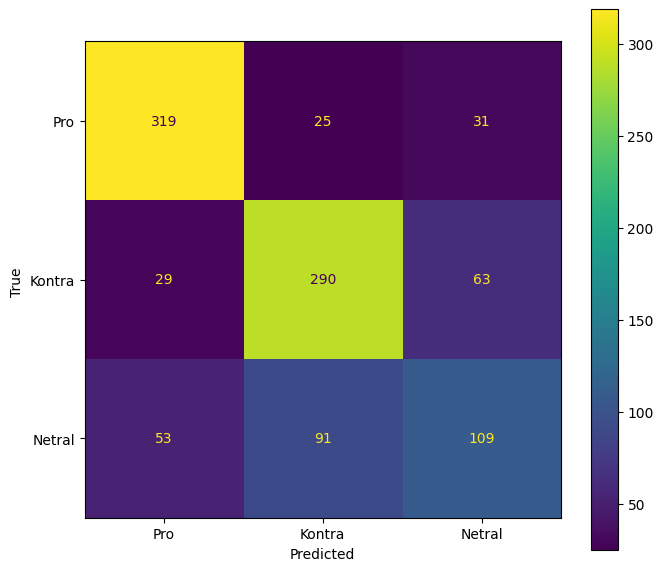

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Hitung confusion matrix
cm = confusion_matrix(
    all_y_true,
    all_y_pred,
    labels=[0, 1, 2]
)

# Tampilkan confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pro", "Kontra", "Netral"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="viridis",
    values_format="d"
)

# plt.title("Confusion Matrix IndoBERT - Stratified 5-Fold HPO")
plt.xlabel("Predicted")
plt.ylabel("True ")
plt.tight_layout()
plt.show()

In [44]:
model.save_pretrained("models/indobert_hpo")
tokenizer.save_pretrained("models/indobert_hpo")

('models/indobert_hpo/tokenizer_config.json',
 'models/indobert_hpo/special_tokens_map.json',
 'models/indobert_hpo/vocab.txt',
 'models/indobert_hpo/added_tokens.json',
 'models/indobert_hpo/tokenizer.json')

In [45]:
from google.colab import files

# Ensure the file exists before attempting to download
if os.path.exists('/content/model.safetensors'):
    files.download('/content/model.safetensors')
else:
    print('File /content/model.safetensors not found.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#PREDIKSI

In [ ]:
import torch
import numpy as np
from datasets import Dataset

# =========================================================
# LABEL
# =========================================================

id2label = {
    0: "Pro",
    1: "Kontra",
    2: "Netral"
}

# =========================================================
# FUNGSI PREDIKSI
# =========================================================

def predict_stance(text):

    # Dataset baru
    new_dataset = Dataset.from_dict({
        "text": [text]
    })

    # Tokenisasi
    new_dataset = new_dataset.map(
        lambda x: tokenizer(
            x["text"],
            padding="max_length",
            truncation=True,
            max_length=BEST_MAX_LENGTH
        ),
        batched=True
    )

    # Format tensor
    new_dataset.set_format(
        type="torch",
        columns=[
            "input_ids",
            "attention_mask"
        ]
    )

    # Prediksi menggunakan FINAL MODEL
    prediction = trainer.predict(
        new_dataset
    )

    # Logits
    logits = prediction.predictions[0]

    # Probabilitas
    probs = torch.softmax(
        torch.tensor(logits),
        dim=0
    ).numpy()

    # Prediksi kelas
    pred = np.argmax(probs)

    return {
        "Prediksi": id2label[pred],
        "Probabilitas": probs
    }

In [ ]:
kalimat = (
    "Semoga aja program ini bakal sukses wujudin program kethanan pangan"
)

hasil = predict_stance(kalimat)

print("Kalimat:")
print(kalimat)

print("\nPrediksi :", hasil["Prediksi"])

print(
    f"Pro     : "
    f"{hasil['Probabilitas'][0] * 100:.2f}%"
)

print(
    f"Kontra  : "
    f"{hasil['Probabilitas'][1] * 100:.2f}%"
)

print(
    f"Netral  : "
    f"{hasil['Probabilitas'][2] * 100:.2f}%"
)

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Kalimat:
Semoga aja program ini bakal sukses wujudin program kethanan pangan

Prediksi : Pro
Pro     : 95.53%
Kontra  : 0.88%
Netral  : 3.59%


In [ ]:
kalimat = (
    "Agak pesimis sih tapi kita percayakan aja pada pemerintah"
)

hasil = predict_stance(kalimat)

print("Kalimat:")
print(kalimat)

print("\nPrediksi :", hasil["Prediksi"])

print(
    f"Pro     : "
    f"{hasil['Probabilitas'][0] * 100:.2f}%"
)

print(
    f"Kontra  : "
    f"{hasil['Probabilitas'][1] * 100:.2f}%"
)

print(
    f"Netral  : "
    f"{hasil['Probabilitas'][2] * 100:.2f}%"
)

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Kalimat:
Agak pesimis sih tapi kita percayakan aja pada pemerintah

Prediksi : Netral
Pro     : 24.08%
Kontra  : 11.96%
Netral  : 63.96%


In [ ]:
kalimat = (
    "Program ga jelas, buang-buang anggaran saja"
)

hasil = predict_stance(kalimat)

print("Kalimat:")
print(kalimat)

print("\nPrediksi :", hasil["Prediksi"])

print(
    f"Pro     : "
    f"{hasil['Probabilitas'][0] * 100:.2f}%"
)

print(
    f"Kontra  : "
    f"{hasil['Probabilitas'][1] * 100:.2f}%"
)

print(
    f"Netral  : "
    f"{hasil['Probabilitas'][2] * 100:.2f}%"
)

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Kalimat:
Program ga jelas, buang-buang anggaran saja

Prediksi : Kontra
Pro     : 2.98%
Kontra  : 54.45%
Netral  : 42.57%


In [ ]:
kalimat = (
    "yakin banget gue ini bakal menjadi program yang gagal total"
)

hasil = predict_stance(kalimat)

print("Kalimat:")
print(kalimat)

print("\nPrediksi :", hasil["Prediksi"])

print(
    f"Pro     : "
    f"{hasil['Probabilitas'][0] * 100:.2f}%"
)

print(
    f"Kontra  : "
    f"{hasil['Probabilitas'][1] * 100:.2f}%"
)

print(
    f"Netral  : "
    f"{hasil['Probabilitas'][2] * 100:.2f}%"
)

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Kalimat:
yakin banget gue ini bakal menjadi program yang gagal total

Prediksi : Kontra
Pro     : 15.55%
Kontra  : 49.48%
Netral  : 34.97%


In [ ]:
kalimat = (
    "no komen, lihat aja ke depannya bakal gmna"
)

hasil = predict_stance(kalimat)

print("Kalimat:")
print(kalimat)

print("\nPrediksi :", hasil["Prediksi"])

print(
    f"Pro     : "
    f"{hasil['Probabilitas'][0] * 100:.2f}%"
)

print(
    f"Kontra  : "
    f"{hasil['Probabilitas'][1] * 100:.2f}%"
)

print(
    f"Netral  : "
    f"{hasil['Probabilitas'][2] * 100:.2f}%"
)

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Kalimat:
no komen, lihat aja ke depannya bakal gmna

Prediksi : Netral
Pro     : 7.38%
Kontra  : 23.87%
Netral  : 68.75%


In [ ]:
kalimat = (
    "saya nyimak aja bro, ga tau apa-apa soal program ini"
)

hasil = predict_stance(kalimat)

print("Kalimat:")
print(kalimat)

print("\nPrediksi :", hasil["Prediksi"])

print(
    f"Pro     : "
    f"{hasil['Probabilitas'][0] * 100:.2f}%"
)

print(
    f"Kontra  : "
    f"{hasil['Probabilitas'][1] * 100:.2f}%"
)

print(
    f"Netral  : "
    f"{hasil['Probabilitas'][2] * 100:.2f}%"
)

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Kalimat:
saya nyimak aja bro, ga tau apa-apa soal program ini

Prediksi : Netral
Pro     : 9.81%
Kontra  : 23.43%
Netral  : 66.76%
